In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.linear_model import Lasso

from sklearn.cross_decomposition import PLSRegression
from sklearn.neural_network import MLPRegressor

df_red = pd.read_csv('winequality-red.csv', sep=';')
df_white = pd.read_csv('winequality-white.csv', sep=';')

feature_cols = [c for c in df_red.columns if c != 'quality']
target_col = 'quality'

print(f"Dimensões do vinho tinto : N = {df_red.shape[0]}, D = {len(feature_cols)}")
print(f"Dimensões do vinho branco: N = {df_white.shape[0]}, D = {len(feature_cols)}")


Dimensões do vinho tinto : N = 1599, D = 11
Dimensões do vinho branco: N = 4898, D = 11


Relembrando Matriz de correlação para cada tipo de vinho:

ANTES E DEPOIS:
                      Skew_Tinto_Antes  Skew_Tinto_Depois  Skew_Branco_Antes  \
fixed acidity                    0.983              0.456              0.648   
volatile acidity                 0.672              0.672              1.577   
citric acid                      0.318              0.318              1.282   
residual sugar                   4.541              2.255              1.077   
chlorides                        5.680              5.071              5.023   
free sulfur dioxide              1.251             -0.097              1.407   
total sulfur dioxide             1.516             -0.036              0.391   
density                          0.071              0.071              0.978   
pH                               0.194              0.194              0.458   
sulphates                        2.429              1.610              0.977   
alcohol                          0.861              0.678              0.487   

                      S

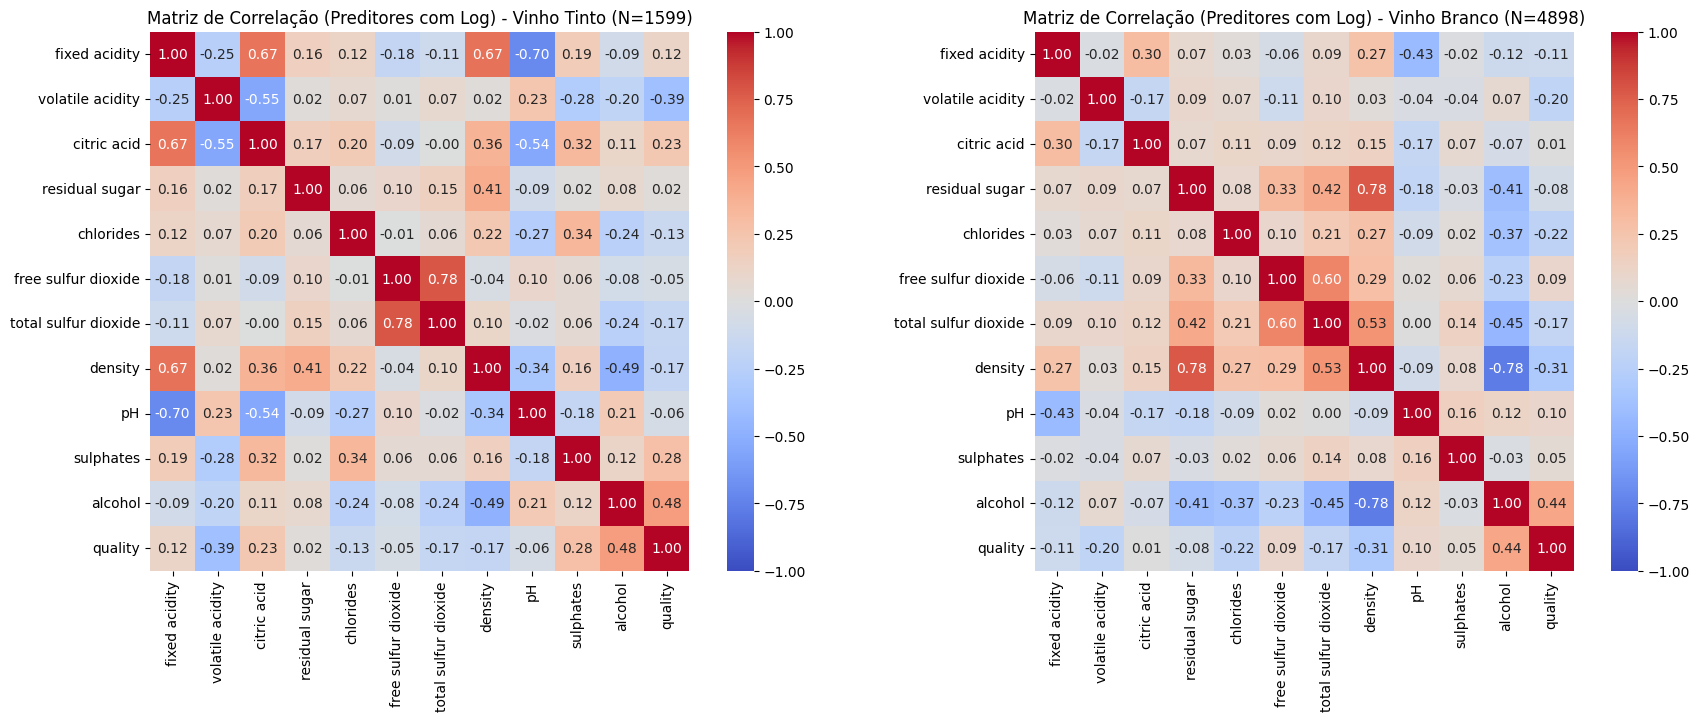

Correlacao de cada preditor com a saida Qualidade:
                      Corr_Tinto_Quality  Corr_Branco_Quality
alcohol                           0.4770               0.4356
sulphates                         0.2810               0.0484
citric acid                       0.2264               0.0060
fixed acidity                     0.1157              -0.1137
residual sugar                    0.0217              -0.0753
free sulfur dioxide              -0.0503               0.0949
pH                               -0.0577               0.0994
chlorides                        -0.1348              -0.2160
total sulfur dioxide             -0.1714              -0.1747
density                          -0.1749              -0.3074
volatile acidity                 -0.3906              -0.1957


In [68]:
# Tratando assimetria antes:
feature_cols = [c for c in df_red.columns if c != 'quality']
target_col = 'quality'


skew_red_orig = df_red[feature_cols].skew()
skew_white_orig = df_white[feature_cols].skew()

# Criterio: (|skew| > 0.75)
skew_threshold = 0.75
cols_to_transform_red = skew_red_orig[skew_red_orig.abs() > skew_threshold].index.tolist()
cols_to_transform_white = skew_white_orig[skew_white_orig.abs() > skew_threshold].index.tolist()

# Transformação logarítmica: log(1 + x)
df_red_log = df_red.copy()
df_white_log = df_white.copy()

for col in cols_to_transform_red:
    df_red_log[col] = np.log1p(df_red_log[col])

for col in cols_to_transform_white:
    df_white_log[col] = np.log1p(df_white_log[col])


skew_red_trans = df_red_log[feature_cols].skew()
skew_white_trans = df_white_log[feature_cols].skew()

df_skewness_report = pd.DataFrame({
    'Skew_Tinto_Antes': skew_red_orig,
    'Skew_Tinto_Depois': skew_red_trans,
    'Skew_Branco_Antes': skew_white_orig,
    'Skew_Branco_Depois': skew_white_trans
})


print("ANTES E DEPOIS:")
print(df_skewness_report.round(3))

# Matrizes de correlacao
corr_red = df_red_log.corr(method='pearson')
corr_white = df_white_log.corr(method='pearson')


fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(corr_red, annot=True, fmt=".2f", cmap='coolwarm', cbar=True,
            square=True, ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Matriz de Correlação (Preditores com Log) - Vinho Tinto (N=1599)")

sns.heatmap(corr_white, annot=True, fmt=".2f", cmap='coolwarm', cbar=True,
            square=True, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("Matriz de Correlação (Preditores com Log) - Vinho Branco (N=4898)")

plt.tight_layout()
plt.show()

corr_outcome = pd.DataFrame({
    'Corr_Tinto_Quality': corr_red[target_col].drop(target_col),
    'Corr_Branco_Quality': corr_white[target_col].drop(target_col)
}).sort_values(by='Corr_Tinto_Quality', ascending=False)


print("Correlacao de cada preditor com a saida Qualidade:")

print(corr_outcome.round(4))

Dividindo as bases de dados em treino e teste:

In [72]:
# Divisao: Treino (70%) e Teste(30%)

# Divisão Vinho Tinto
X_red = df_red_log[feature_cols]
y_red = df_red_log[target_col]
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_red, y_red, test_size=0.30, random_state=42
)

# Divisão Vinho Branco
X_white = df_white_log[feature_cols]
y_white = df_white_log[target_col]
X_train_white, X_test_white, y_train_white, y_test_white = train_test_split(
    X_white, y_white, test_size=0.30, random_state=42
)

print("\nTamanhos dos Conjuntos: ")
print(f"Tinto  -> Treino: {X_train_red.shape[0]} amostras. Teste: {X_test_red.shape[0]} amostras")
print(f"Branco -> Treino: {X_train_white.shape[0]} amostras. Teste: {X_test_white.shape[0]} amostras")



Tamanhos dos Conjuntos: 
Tinto  -> Treino: 1119 amostras. Teste: 480 amostras
Branco -> Treino: 3428 amostras. Teste: 1470 amostras


Criando função responsável por montar a matriz de design:

In [73]:
def build_design_matrix(data, feature_cols=None, target_col=None, add_intercept=True):


    if isinstance(data, pd.DataFrame):
        if feature_cols is None:

            feature_cols = [c for c in data.columns if c != target_col]
        X = data[feature_cols].to_numpy(dtype=float)

        y = None
        if target_col is not None and target_col in data.columns:
            y = data[target_col].to_numpy(dtype=float).reshape(-1, 1)
    else:

        X = np.array(data, dtype=float)
        y = None

    # Concatenacao da coluna de '1' para o intercepto (beta 0)
    if add_intercept:
        N = X.shape[0]
        ones = np.ones((N, 1), dtype=float)
        X = np.hstack([ones, X])

    if y is not None:
        return X, y
    return X

Criando as matrizes de design X e Y para cada base de dados:

In [74]:

X_mat_train_red = build_design_matrix(X_train_red, add_intercept=True)
y_mat_train_red = y_train_red.to_numpy(dtype=float).reshape(-1, 1)


X_mat_train_white = build_design_matrix(X_train_white, add_intercept=True)
y_mat_train_white = y_train_white.to_numpy(dtype=float).reshape(-1, 1)

# Verificacao das dimensoes resultantes:
print("Dimensoes das matrizes de treino: ")
print(f"X_mat_train_red  : {X_mat_train_red.shape}")
print(f"y_mat_train_red  : {y_mat_train_red.shape}")
print(f"X_mat_train_white: {X_mat_train_white.shape}")
print(f"y_mat_train_white: {y_mat_train_white.shape}")

Dimensoes das matrizes de treino: 
X_mat_train_red  : (1119, 12)
y_mat_train_red  : (1119, 1)
X_mat_train_white: (3428, 12)
y_mat_train_white: (3428, 1)


Funções para calcular inversa e transposta:

In [75]:
def compute_transpose(matrix):
    return np.transpose(matrix)  # ou matrix.T


def compute_inverse(matrix):
    return np.linalg.inv(matrix)

def compute_matmul(matrix_a, matrix_b):
    return np.matmul(matrix_a, matrix_b)  # ou matrix_a @ matrix_b

Juntando tudo em uma função que calcula OLS:

In [76]:
def fit_ols(X, Y, feature_names=None):
    # 1. X^T
    X_T = compute_transpose(X)

    # 2. X^T @ X
    XtX = compute_matmul(X_T, X)

    # 3. (X^T @ X)^(-1)
    XtX_inv = compute_inverse(XtX)

    # 4. X^T @ Y
    XtY = compute_matmul(X_T, Y)

    # 5. beta_hat = (X^T @ X)^(-1) @ (X^T @ Y)
    beta_hat = compute_matmul(XtX_inv, XtY)

    # Se uma lista de nomes for fornecida, organiza em DataFrame
    if feature_names is not None:
        names = ['intercept'] + list(feature_names) if len(feature_names) == (X.shape[1] - 1) else feature_names
        df_beta = pd.DataFrame({
            'Preditor': names,
            'Beta_Hat': beta_hat.flatten()
        })
        return beta_hat, df_beta

    return beta_hat

Alcançando os valores OLS das duas bases de dados:

In [77]:
# Lista com os 11 preditores físico-químicos
features = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

# 1. Estimação para o Vinho Tinto
beta_hat_red, df_beta_red = fit_ols(
    X=X_mat_train_red,
    Y=y_mat_train_red,
    feature_names=features
)

# 2. Estimação para o Vinho Branco
beta_hat_white, df_beta_white = fit_ols(
    X=X_mat_train_white,
    Y=y_mat_train_white,
    feature_names=features
)

# Comparativo dos coeficientes estimados (beta chapéu)
df_comparativo = pd.DataFrame({
    'Preditor': df_beta_red['Preditor'],
    'Beta_Hat_Tinto': df_beta_red['Beta_Hat'],
    'Beta_Hat_Branco': df_beta_white['Beta_Hat']
})

print(df_comparativo.to_string(index=False))

            Preditor  Beta_Hat_Tinto  Beta_Hat_Branco
           intercept       37.358983        47.832478
       fixed acidity        0.607202        -0.013818
    volatile acidity       -1.105802        -2.472894
         citric acid       -0.358115        -0.052665
      residual sugar        0.110809         0.245423
           chlorides       -1.769807        -0.362238
 free sulfur dioxide        0.105697         0.335218
total sulfur dioxide       -0.153211        -0.002010
             density      -40.429776       -68.252033
                  pH       -0.104113         0.278353
           sulphates        1.690853         0.909510
             alcohol        3.163988         0.314644


Criando função de avaliação de regressão, que, dado uma matriz B^, avalia seu erro a partir de um conjunto de treino (x_train e y_train)

In [41]:
def evaluate_regression(beta_hat, X_test, y_test):

    y_true = np.array(y_test, dtype=float).reshape(-1, 1)

    y_pred = compute_matmul(X_test, beta_hat)

    residuals = y_true - y_pred

    rmse = np.sqrt(np.mean(residuals ** 2))

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot)

    return float(rmse), float(r2), y_pred

Avaliando o modelo criado por OLS simples com divisão de 70/30, sem Cross-validation:

(Pegando os coeficientes OLS do modelo gerado no treino e aplicando diretamente sobre o conjunto de 30% dos dados de teste, em seguida, comparando com os y referente a esses mesmos dados de teste)

In [42]:
X_mat_test_red = build_design_matrix(X_test_red, add_intercept=True)
y_mat_test_red = y_test_red.to_numpy(dtype=float).reshape(-1, 1)

X_mat_test_white = build_design_matrix(X_test_white, add_intercept=True)
y_mat_test_white = y_test_white.to_numpy(dtype=float).reshape(-1, 1)

# Avaliacao no Vinho Tinto
rmse_red, r2_red, y_pred_red = evaluate_regression(
    beta_hat=beta_hat_red,
    X_test=X_mat_test_red,
    y_test=y_mat_test_red
)

# Avaliacao no Vinho Branco
rmse_white, r2_white, y_pred_white = evaluate_regression(
    beta_hat=beta_hat_white,
    X_test=X_mat_test_white,
    y_test=y_mat_test_white
)

print("Resultados no conjunto de teste (30%)")
print(f"Vinho Tinto:  RMSE: {rmse_red:.4f}, R²: {r2_red:.4f}")
print(f"Vinho Branco: RMSE: {rmse_white:.4f}, R²: {r2_white:.4f}")

Resultados no conjunto de teste (30%)
Vinho Tinto:  RMSE: 0.6412, R²: 0.3515
Vinho Branco: RMSE: 0.7328, R²: 0.2887


Definindo uma forma mais inteligente de testar o modelo: cross-validation

In [43]:
def cross_validation_ols(X, y, k=5, shuffle=True, random_state=42):

    y_vec = np.array(y, dtype=float).reshape(-1, 1)
    N = X.shape[0]


    indices = np.arange(N)
    if shuffle:
        rng = np.random.default_rng(random_state)
        indices = rng.permutation(indices)

    #Dividindo indices em K partes
    folds_indices = np.array_split(indices, k)

    fold_records = []


    for fold_num in range(k):

        val_idx = folds_indices[fold_num]


        train_idx = np.setdiff1d(indices, val_idx)

        X_tr, y_tr = X[train_idx], y_vec[train_idx]
        X_val, y_val = X[val_idx], y_vec[val_idx]


        beta_fold = fit_ols(X_tr, y_tr)


        rmse_val, r2_val, _ = evaluate_regression(beta_fold, X_val, y_val)

        fold_records.append({
            'Fold': fold_num + 1,
            'N_Treino': len(train_idx),
            'N_Validacao': len(val_idx),
            'RMSE': rmse_val,
            'R2': r2_val,
            'beta_hat': beta_fold
        })


    df_folds = pd.DataFrame(fold_records)


    best_idx = df_folds['RMSE'].idxmin()
    best_fold_info = df_folds.loc[best_idx].to_dict()

    cv_summary = {
        'K': k,
        'RMSE_mean': float(df_folds['RMSE'].mean()),
        'RMSE_std': float(df_folds['RMSE'].std()),
        'R2_mean': float(df_folds['R2'].mean()),
        'R2_std': float(df_folds['R2'].std())
    }

    return cv_summary, df_folds, best_fold_info

Procurando melhor Fold

In [44]:
summary_red, df_folds_red, best_fold_red = cross_validation_ols(
    X=X_mat_train_red,
    y=y_mat_train_red,
    k=5,
    shuffle=True,
    random_state=42
)

print("\n")
print("Resultados por Fold (vinho tinto) ")
print("\n")
print(df_folds_red[['Fold', 'N_Treino', 'N_Validacao', 'RMSE', 'R2']].to_string(index=False))
print(f"\nMelhor Subdivisao: Fold {best_fold_red['Fold']} (Menor RMSE: {best_fold_red['RMSE']:.4f}, R²: {best_fold_red['R2']:.4f})")
print("\n Media da validacao cruzada:")
print(f"RMSE Medio: {summary_red['RMSE_mean']:.4f} ± {summary_red['RMSE_std']:.4f}")
print(f"R² Medio  : {summary_red['R2_mean']:.4f} ± {summary_red['R2_std']:.4f}")


summary_white, df_folds_white, best_fold_white = cross_validation_ols(
    X=X_mat_train_white,
    y=y_mat_train_white,
    k=5,
    shuffle=True,
    random_state=42
)

print("\n")
print("Resultados por Fold (vinho branco)")
print("\n")
print(df_folds_white[['Fold', 'N_Treino', 'N_Validacao', 'RMSE', 'R2']].to_string(index=False))
print(f"\nMelhor Subdivisão: Fold {best_fold_white['Fold']} (Menor RMSE: {best_fold_white['RMSE']:.4f}, R²: {best_fold_white['R2']:.4f})")
print("Media de validacao cruzada: ")
print(f"RMSE Médio: {summary_white['RMSE_mean']:.4f} ± {summary_white['RMSE_std']:.4f}")
print(f"R² Médio  : {summary_white['R2_mean']:.4f} ± {summary_white['R2_std']:.4f}")

#tabela comparativa
df_comparacao_cv = pd.DataFrame({
    'Tipo': ['Vinho Tinto', 'Vinho Branco'],
    'RMSE_CV (Média ± DP)': [
        f"{summary_red['RMSE_mean']:.4f} ± {summary_red['RMSE_std']:.4f}",
        f"{summary_white['RMSE_mean']:.4f} ± {summary_white['RMSE_std']:.4f}"
    ],
    'R²_CV (Média ± DP)': [
        f"{summary_red['R2_mean']:.4f} ± {summary_red['R2_std']:.4f}",
        f"{summary_white['R2_mean']:.4f} ± {summary_white['R2_std']:.4f}"
    ]
})

print("\n")
print("Resumo comparativo")
print("\n")
print(df_comparacao_cv.to_string(index=False))



Resultados por Fold (vinho tinto) 


 Fold  N_Treino  N_Validacao     RMSE       R2
    1       895          224 0.701630 0.355658
    2       895          224 0.665400 0.384793
    3       895          224 0.581529 0.368644
    4       895          224 0.662676 0.293389
    5       896          223 0.666480 0.318143

Melhor Subdivisao: Fold 3 (Menor RMSE: 0.5815, R²: 0.3686)

 Media da validacao cruzada:
RMSE Medio: 0.6555 ± 0.0444
R² Medio  : 0.3441 ± 0.0375


Resultados por Fold (vinho branco)


 Fold  N_Treino  N_Validacao     RMSE       R2
    1      2742          686 0.780403 0.260714
    2      2742          686 0.742020 0.255096
    3      2742          686 0.750590 0.304766
    4      2743          685 0.726308 0.343510
    5      2743          685 0.762986 0.274429

Melhor Subdivisão: Fold 4 (Menor RMSE: 0.7263, R²: 0.3435)
Media de validacao cruzada: 
RMSE Médio: 0.7525 ± 0.0205
R² Médio  : 0.2877 ± 0.0367


Resumo comparativo


        Tipo RMSE_CV (Média ± DP) R²_CV (Méd

Comparando com modelo built-in:



Comparacao dos coeficientes Beta:
            Preditor  Beta_Scratch  Beta_Builtin  Diferenca_Absoluta
           intercept     37.358983     37.358983        4.052218e-09
       fixed acidity      0.607202      0.607202        9.198309e-12
    volatile acidity     -1.105802     -1.105802        2.525535e-12
         citric acid     -0.358115     -0.358115        9.033552e-12
      residual sugar      0.110809      0.110809        2.487816e-12
           chlorides     -1.769807     -1.769807        1.148992e-11
 free sulfur dioxide      0.105697      0.105697        6.652456e-13
total sulfur dioxide     -0.153211     -0.153211        1.759703e-13
             density    -40.429776    -40.429776        2.385740e-09
                  pH     -0.104113     -0.104113        6.879053e-12
           sulphates      1.690853      1.690853        3.215650e-12
             alcohol      3.163988      3.163988        1.030775e-11


Comparacao no conjunto de teste:
Scratch : RMSE: 0.641221 | R²: 0.3

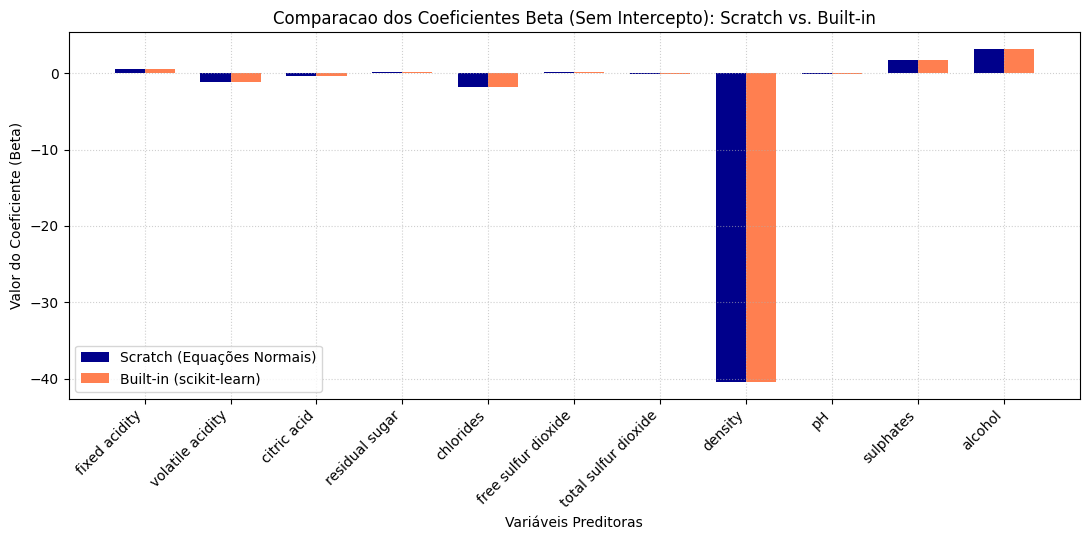

In [45]:

beta_scratch = fit_ols(X_mat_train_red, y_mat_train_red)
rmse_ts_sc, r2_ts_sc, y_pred_sc = evaluate_regression(beta_scratch, X_mat_test_red, y_mat_test_red)


lr_builtin = LinearRegression(fit_intercept=True)
lr_builtin.fit(X_train_red, y_train_red)
y_pred_sk = lr_builtin.predict(X_test_red)

rmse_ts_sk = float(np.sqrt(mean_squared_error(y_test_red, y_pred_sk)))
r2_ts_sk = float(r2_score(y_test_red, y_pred_sk))


beta_builtin = np.concatenate([[lr_builtin.intercept_], lr_builtin.coef_]).reshape(-1, 1)

features_all = ['intercept'] + [c for c in X_train_red.columns]
df_compare_betas = pd.DataFrame({
    'Preditor': features_all,
    'Beta_Scratch': beta_scratch.flatten(),
    'Beta_Builtin': beta_builtin.flatten(),
    'Diferenca_Absoluta': np.abs(beta_scratch.flatten() - beta_builtin.flatten())
})


print("Comparacao dos coeficientes Beta:")

print(df_compare_betas.to_string(index=False))

print("\n")
print("Comparacao no conjunto de teste:")

print(f"Scratch : RMSE: {rmse_ts_sc:.6f} | R²: {r2_ts_sc:.6f}")
print(f"Built-in : RMSE: {rmse_ts_sk:.6f} | R²: {r2_ts_sk:.6f}")
print(f"Diferença : RMSE: {abs(rmse_ts_sc - rmse_ts_sk):.2e} | R²: {abs(r2_ts_sc - r2_ts_sk):.2e}")


kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_red)):

    b_sc = fit_ols(X_mat_train_red[tr_idx], y_mat_train_red[tr_idx])
    rmse_fold_sc, r2_fold_sc, _ = evaluate_regression(b_sc, X_mat_train_red[val_idx], y_mat_train_red[val_idx])


    lr_fold = LinearRegression(fit_intercept=True).fit(X_train_red.iloc[tr_idx], y_train_red.iloc[tr_idx])
    pred_val_sk = lr_fold.predict(X_train_red.iloc[val_idx])
    rmse_fold_sk = float(np.sqrt(mean_squared_error(y_train_red.iloc[val_idx], pred_val_sk)))
    r2_fold_sk = float(r2_score(y_train_red.iloc[val_idx], pred_val_sk))

    cv_records.append({
        'Fold': fold + 1,
        'RMSE_Scratch': rmse_fold_sc,
        'RMSE_Builtin': rmse_fold_sk,
        'Diff_RMSE': abs(rmse_fold_sc - rmse_fold_sk),
        'R2_Scratch': r2_fold_sc,
        'R2_Builtin': r2_fold_sk,
        'Diff_R2': abs(r2_fold_sc - r2_fold_sk)
    })

df_cv_compare = pd.DataFrame(cv_records)
print("\nComparacao fold a fold por validacao cruzada: ")

print(df_cv_compare[['Fold', 'RMSE_Scratch', 'RMSE_Builtin', 'R2_Scratch', 'R2_Builtin']].to_string(index=False))


coef_scratch_no_bias = beta_scratch[1:].flatten()
coef_builtin_no_bias = lr_builtin.coef_
pred_labels = [c for c in X_train_red.columns]

x_pos = np.arange(len(pred_labels))
width = 0.35

plt.figure(figsize=(11, 5.5))

# Barras lado a lado
plt.bar(x_pos - width/2, coef_scratch_no_bias, width, label='Scratch (Equações Normais)', color='darkblue')
plt.bar(x_pos + width/2, coef_builtin_no_bias, width, label='Built-in (scikit-learn)', color='coral')


plt.xticks(x_pos, pred_labels, rotation=45, ha='right', fontsize=10)
plt.title("Comparacao dos Coeficientes Beta (Sem Intercepto): Scratch vs. Built-in", fontsize=12)
plt.ylabel("Valor do Coeficiente (Beta)")
plt.xlabel("Variáveis Preditoras")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

LASSO:

Para aplicar o método Lasso, vamos primeiro padronizar os dados:

In [46]:
def standardize_features(X_train, X_test=None):

    # Converte para array numpy se for DataFrame
    is_df = isinstance(X_train, pd.DataFrame)
    columns = X_train.columns if is_df else None

    X_tr = np.array(X_train, dtype=float)


    mu = np.mean(X_tr, axis=0)
    sigma = np.std(X_tr, axis=0, ddof=0)


    sigma_adj = np.where(sigma == 0, 1.0, sigma)


    X_tr_scaled = (X_tr - mu) / sigma_adj

    scaler_params = {
        'mean': mu,
        'std': sigma,
        'feature_names': columns
    }


    if X_test is not None:
        X_ts = np.array(X_test, dtype=float)
        X_ts_scaled = (X_ts - mu) / sigma_adj

        if is_df:
            X_tr_scaled = pd.DataFrame(X_tr_scaled, columns=columns, index=X_train.index)
            X_ts_scaled = pd.DataFrame(X_ts_scaled, columns=columns, index=X_test.index)

        return X_tr_scaled, X_ts_scaled, scaler_params

    if is_df:
        X_tr_scaled = pd.DataFrame(X_tr_scaled, columns=columns, index=X_train.index)

    return X_tr_scaled, scaler_params

Padronizando os dados:

In [47]:

#vinho tinto
X_train_red_scaled, X_test_red_scaled, params_red = standardize_features(
    X_train=X_train_red,
    X_test=X_test_red
)

#vinho branco
X_train_white_scaled, X_test_white_scaled, params_white = standardize_features(
    X_train=X_train_white,
    X_test=X_test_white
)

Implementando Lasso na mão:

In [48]:
def soft_threshold(z, gamma):

    if z > gamma:
        return z - gamma
    elif z < -gamma:
        return z + gamma
    else:
        return 0.0


def fit_lasso_coordinate_descent(X, y, alpha=0.01, max_iter=2000, tol=1e-5):

    X_arr = np.array(X, dtype=float)
    y_arr = np.array(y, dtype=float).flatten()

    N, D = X_arr.shape


    y_mean = np.mean(y_arr)
    y_cent = y_arr - y_mean


    col_norm_sq = np.sum(X_arr ** 2, axis=0)


    beta = np.zeros(D, dtype=float)


    for iteration in range(max_iter):
        beta_old = beta.copy()

        for j in range(D):

            r_j = y_cent - (X_arr @ beta - X_arr[:, j] * beta[j])


            rho_j = np.dot(X_arr[:, j], r_j)


            beta[j] = soft_threshold(rho_j, N * alpha) / col_norm_sq[j]


        if np.max(np.abs(beta - beta_old)) < tol:
            break

    return y_mean, beta

Teste rápido com alpha = 0.05:

In [49]:

intercept_red, beta_lasso_red = fit_lasso_coordinate_descent(
    X=X_train_red_scaled,
    y=y_train_red,
    alpha=0.05
)


df_lasso_teste = pd.DataFrame({
    'Preditor': feature_cols,
    'Beta_Lasso': beta_lasso_red
})

print("Intercepto (beta_0):", intercept_red)
print("\n Coeficientes estimados com Lasso (alpha=0.05) ")
print(df_lasso_teste.to_string(index=False))

Intercepto (beta_0): 5.621983914209116

 Coeficientes estimados com Lasso (alpha=0.05) 
            Preditor  Beta_Lasso
       fixed acidity    0.000000
    volatile acidity   -0.171773
         citric acid    0.000000
      residual sugar    0.000000
           chlorides   -0.011755
 free sulfur dioxide    0.000000
total sulfur dioxide   -0.016816
             density    0.000000
                  pH    0.000000
           sulphates    0.087167
             alcohol    0.296236


Implementando cross-validation:

In [50]:
def cross_validate_lasso_grid(X_train, y_train, lambdas, k=5, random_state=42):

    X_arr = np.array(X_train, dtype=float)
    y_arr = np.array(y_train, dtype=float).flatten()

    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    grid_records = []

    for lam in lambdas:
        fold_rmses = []
        fold_r2s = []

        for train_idx, val_idx in kf.split(X_arr):
            X_tr, y_tr = X_arr[train_idx], y_arr[train_idx]
            X_val, y_val = X_arr[val_idx], y_arr[val_idx]


            intercept, beta = fit_lasso_coordinate_descent(X_tr, y_tr, alpha=lam)


            y_pred_val = intercept + X_val @ beta
            residuals = y_val - y_pred_val

            rmse_val = np.sqrt(np.mean(residuals ** 2))
            ss_res = np.sum(residuals ** 2)
            ss_tot = np.sum((y_val - np.mean(y_val)) ** 2)
            r2_val = 1.0 - (ss_res / ss_tot)

            fold_rmses.append(rmse_val)
            fold_r2s.append(r2_val)

        grid_records.append({
            'lambda': float(lam),
            'log10_lambda': float(np.log10(lam)),
            'RMSE_mean': float(np.mean(fold_rmses)),
            'RMSE_std': float(np.std(fold_rmses, ddof=1)),
            'R2_mean': float(np.mean(fold_r2s)),
            'R2_std': float(np.std(fold_r2s, ddof=1))
        })

    df_results = pd.DataFrame(grid_records)

    # Identificação do lambda ótimo (menor RMSE médio)
    best_idx = df_results['RMSE_mean'].idxmin()
    best_lambda = df_results.loc[best_idx, 'lambda']

    return df_results, best_lambda

Busca pelo Lambda ótimo

In [51]:

lambda_grid = np.logspace(-4, 0, 15)

df_cv_lasso_red, best_lambda_red = cross_validate_lasso_grid(
    X_train=X_train_red_scaled,
    y_train=y_train_red,
    lambdas=lambda_grid,
    k=5,
    random_state=42
)

print("\n")
print("Resultados em grade (vinho tinto)")
print("\n")
print(df_cv_lasso_red[['lambda', 'RMSE_mean', 'RMSE_std', 'R2_mean', 'R2_std']].to_string(index=False))

print("\n")
best_row = df_cv_lasso_red[df_cv_lasso_red['lambda'] == best_lambda_red].iloc[0]
print(f"Lambda otimo encontrado (Tinto): λ = {best_lambda_red:.6f} (10^{np.log10(best_lambda_red):.2f})")
print(f"Desempenho no CV         : RMSE = {best_row['RMSE_mean']:.4f} ± {best_row['RMSE_std']:.4f} | R² = {best_row['R2_mean']:.4f} ± {best_row['R2_std']:.4f}")
print("\n")



Resultados em grade (vinho tinto)


  lambda  RMSE_mean  RMSE_std   R2_mean   R2_std
0.000100   0.660848  0.030700  0.328171 0.077260
0.000193   0.660827  0.030677  0.328223 0.077133
0.000373   0.660788  0.030632  0.328320 0.076887
0.000720   0.660739  0.030563  0.328457 0.076386
0.001389   0.660667  0.030434  0.328676 0.075427
0.002683   0.660631  0.030056  0.328877 0.073576
0.005179   0.660605  0.029243  0.329150 0.070154
0.010000   0.660759  0.028232  0.329222 0.064208
0.019307   0.661196  0.026719  0.328971 0.053210
0.037276   0.662504  0.026299  0.327040 0.039188
0.071969   0.669393  0.027291  0.313429 0.029685
0.138950   0.690183  0.030805  0.270529 0.024255
0.268270   0.751691  0.036873  0.135281 0.014487
0.517947   0.812417  0.033982 -0.010550 0.013603
1.000000   0.812417  0.033982 -0.010550 0.013603


Lambda otimo encontrado (Tinto): λ = 0.005179 (10^-2.29)
Desempenho no CV         : RMSE = 0.6606 ± 0.0292 | R² = 0.3292 ± 0.0702




Gerando gráfico para visualizar dinâmica do Lambda

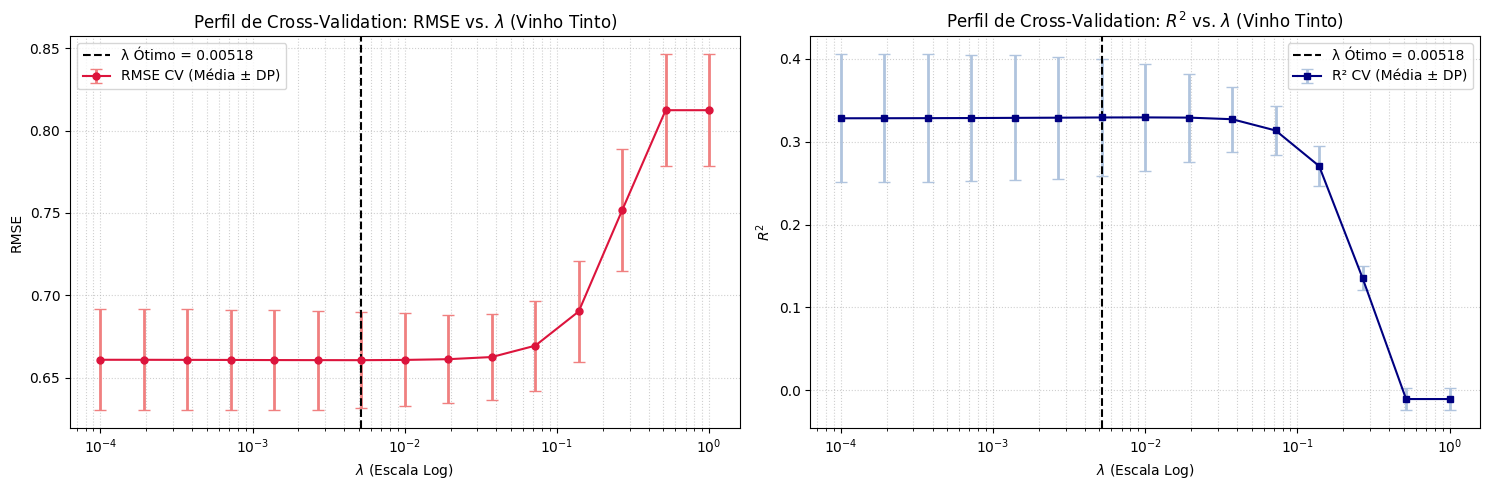

In [52]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Perfil do RMSE
axes[0].errorbar(
    df_cv_lasso_red['lambda'],
    df_cv_lasso_red['RMSE_mean'],
    yerr=df_cv_lasso_red['RMSE_std'],
    fmt='-o', color='crimson', ecolor='lightcoral', elinewidth=2, capsize=4, markersize=5,
    label='RMSE CV (Média ± DP)'
)
axes[0].axvline(best_lambda_red, color='black', linestyle='--', lw=1.5,
                label=f'λ Ótimo = {best_lambda_red:.5f}')
axes[0].set_xscale('log')
axes[0].set_xlabel("$\\lambda$ (Escala Log)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Perfil de Cross-Validation: RMSE vs. $\\lambda$ (Vinho Tinto)")
axes[0].grid(True, which='both', linestyle=':', alpha=0.6)
axes[0].legend()

# Perfil do R²
axes[1].errorbar(
    df_cv_lasso_red['lambda'],
    df_cv_lasso_red['R2_mean'],
    yerr=df_cv_lasso_red['R2_std'],
    fmt='-s', color='navy', ecolor='lightsteelblue', elinewidth=2, capsize=4, markersize=5,
    label='R² CV (Média ± DP)'
)
axes[1].axvline(best_lambda_red, color='black', linestyle='--', lw=1.5,
                label=f'λ Ótimo = {best_lambda_red:.5f}')
axes[1].set_xscale('log')
axes[1].set_xlabel("$\\lambda$ (Escala Log)")
axes[1].set_ylabel("$R^2$")
axes[1].set_title("Perfil de Cross-Validation: $R^2$ vs. $\\lambda$ (Vinho Tinto)")
axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

Mesmo processo para vinho branco:



Resultados para vinho branco: 


  lambda  RMSE_mean  RMSE_std   R2_mean   R2_std
0.000100   0.752056  0.022437  0.288554 0.033903
0.000193   0.752009  0.022375  0.288647 0.033736
0.000373   0.751919  0.022255  0.288824 0.033419
0.000720   0.751752  0.022034  0.289151 0.032828
0.001389   0.751455  0.021640  0.289732 0.031766
0.002683   0.750999  0.021007  0.290627 0.030023
0.005179   0.750911  0.020379  0.290814 0.028582
0.010000   0.750906  0.019253  0.290863 0.025831
0.019307   0.752350  0.018527  0.288135 0.024841
0.037276   0.758392  0.017758  0.276650 0.024201
0.071969   0.771335  0.015984  0.251804 0.019804
0.138950   0.802034  0.013386  0.191101 0.013434
0.268270   0.848211  0.012337  0.095313 0.005471
0.517947   0.892716  0.011745 -0.002131 0.002234
1.000000   0.892716  0.011745 -0.002131 0.002234


Lambda otimo encontrado (Branco): λ = 0.010000 (10^-2.00)
Desempenho no CV                : RMSE = 0.7509 ± 0.0193 | R² = 0.2909 ± 0.0258




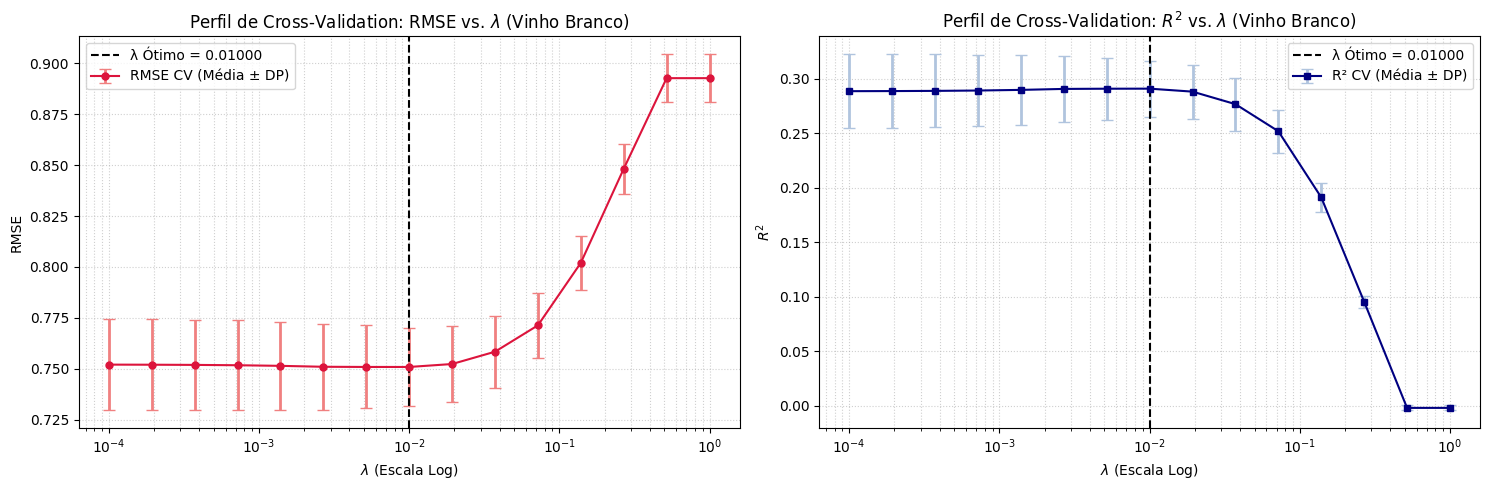

In [53]:

df_cv_lasso_white, best_lambda_white = cross_validate_lasso_grid(
    X_train=X_train_white_scaled,
    y_train=y_train_white,
    lambdas=lambda_grid,
    k=5,
    random_state=42
)

print("\n")
print("Resultados para vinho branco: ")
print("\n")
print(df_cv_lasso_white[['lambda', 'RMSE_mean', 'RMSE_std', 'R2_mean', 'R2_std']].to_string(index=False))

print("\n")
best_row_white = df_cv_lasso_white[df_cv_lasso_white['lambda'] == best_lambda_white].iloc[0]
print(f"Lambda otimo encontrado (Branco): λ = {best_lambda_white:.6f} (10^{np.log10(best_lambda_white):.2f})")
print(f"Desempenho no CV                : RMSE = {best_row_white['RMSE_mean']:.4f} ± {best_row_white['RMSE_std']:.4f} | R² = {best_row_white['R2_mean']:.4f} ± {best_row_white['R2_std']:.4f}")
print("\n")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Perfil do RMSE
axes[0].errorbar(
    df_cv_lasso_white['lambda'],
    df_cv_lasso_white['RMSE_mean'],
    yerr=df_cv_lasso_white['RMSE_std'],
    fmt='-o', color='crimson', ecolor='lightcoral', elinewidth=2, capsize=4, markersize=5,
    label='RMSE CV (Média ± DP)'
)
axes[0].axvline(best_lambda_white, color='black', linestyle='--', lw=1.5,
                label=f'λ Ótimo = {best_lambda_white:.5f}')
axes[0].set_xscale('log')
axes[0].set_xlabel("$\\lambda$ (Escala Log)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Perfil de Cross-Validation: RMSE vs. $\\lambda$ (Vinho Branco)")
axes[0].grid(True, which='both', linestyle=':', alpha=0.6)
axes[0].legend()

#  Perfil do R²
axes[1].errorbar(
    df_cv_lasso_white['lambda'],
    df_cv_lasso_white['R2_mean'],
    yerr=df_cv_lasso_white['R2_std'],
    fmt='-s', color='navy', ecolor='lightsteelblue', elinewidth=2, capsize=4, markersize=5,
    label='R² CV (Média ± DP)'
)
axes[1].axvline(best_lambda_white, color='black', linestyle='--', lw=1.5,
                label=f'λ Ótimo = {best_lambda_white:.5f}')
axes[1].set_xscale('log')
axes[1].set_xlabel("$\\lambda$ (Escala Log)")
axes[1].set_ylabel("$R^2$")
axes[1].set_title("Perfil de Cross-Validation: $R^2$ vs. $\\lambda$ (Vinho Branco)")
axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

Comparando e avaliando novo modelo com penalização no conjunto de teste:

In [54]:

intercept_sc, beta_sc = fit_lasso_coordinate_descent(
    X=X_train_red_scaled,
    y=y_train_red,
    alpha=best_lambda_red
)


y_pred_ts_sc = intercept_sc + X_test_red_scaled.to_numpy() @ beta_sc


residuals_sc = y_test_red.to_numpy().flatten() - y_pred_ts_sc
rmse_ts_sc = float(np.sqrt(np.mean(residuals_sc ** 2)))
ss_tot_sc = np.sum((y_test_red.to_numpy().flatten() - np.mean(y_test_red)) ** 2)
r2_ts_sc = float(1.0 - (np.sum(residuals_sc ** 2) / ss_tot_sc))

lasso_builtin = Lasso(alpha=best_lambda_red, max_iter=2000, tol=1e-5)
lasso_builtin.fit(X_train_red_scaled, y_train_red)

y_pred_ts_sk = lasso_builtin.predict(X_test_red_scaled)
rmse_ts_sk = float(np.sqrt(mean_squared_error(y_test_red, y_pred_ts_sk)))
r2_ts_sk = float(r2_score(y_test_red, y_pred_ts_sk))

# Relatorio final

print(f"Avaliaçao no Conjunto de Teste (λ* = {best_lambda_red:.5f})")

print(f"Scratch: RMSE: {rmse_ts_sc:.6f}, R²: {r2_ts_sc:.6f}")
print(f"Built-in: RMSE: {rmse_ts_sk:.6f}, R²: {r2_ts_sk:.6f}")
print(f"Diferença: RMSE: {abs(rmse_ts_sc - rmse_ts_sk):.2e}, R²: {abs(r2_ts_sc - r2_ts_sk):.2e}")


Avaliaçao no Conjunto de Teste (λ* = 0.00518)
Scratch: RMSE: 0.641706, R²: 0.350518
Built-in: RMSE: 0.641706, R²: 0.350518
Diferença: RMSE: 1.02e-07, R²: 2.06e-07


para Vinho Branco:

In [55]:

intercept_sc_white, beta_sc_white = fit_lasso_coordinate_descent(
    X=X_train_white_scaled,
    y=y_train_white,
    alpha=best_lambda_white
)


y_pred_ts_sc_white = intercept_sc_white + X_test_white_scaled.to_numpy() @ beta_sc_white


residuals_sc_white = y_test_white.to_numpy().flatten() - y_pred_ts_sc_white
rmse_ts_sc_white = float(np.sqrt(np.mean(residuals_sc_white ** 2)))
ss_tot_sc_white = np.sum((y_test_white.to_numpy().flatten() - np.mean(y_test_white)) ** 2)
r2_ts_sc_white = float(1.0 - (np.sum(residuals_sc_white ** 2) / ss_tot_sc_white))



print(f"Avaliacao no Conjunto de Teste (λ* = {best_lambda_white:.5f}) ---")

print(f"Lasso Scratch: RMSE: {rmse_ts_sc_white:.6f}, R²: {r2_ts_sc_white:.6f}")


Avaliacao no Conjunto de Teste (λ* = 0.01000) ---
Lasso Scratch: RMSE: 0.735203, R²: 0.284105


3. PLS

In [56]:
def cross_validate_pls(X_train, y_train, max_components=11, k=5, random_state=42):

    X_arr = np.array(X_train, dtype=float)
    y_arr = np.array(y_train, dtype=float).flatten()

    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    grid_records = []

    # Testar de 1 até max_components (no caso dos vinhos, de 1 a 11)
    for n_comp in range(1, max_components + 1):
        fold_rmses = []
        fold_r2s = []

        for train_idx, val_idx in kf.split(X_arr):
            X_tr, y_tr = X_arr[train_idx], y_arr[train_idx]
            X_val, y_val = X_arr[val_idx], y_arr[val_idx]

            # Ajuste do PLS
            pls = PLSRegression(n_components=n_comp)
            pls.fit(X_tr, y_tr)

            # Predição no fold de validação
            y_pred_val = pls.predict(X_val).flatten()
            residuals = y_val - y_pred_val

            # Métricas
            rmse_val = np.sqrt(np.mean(residuals ** 2))
            ss_res = np.sum(residuals ** 2)
            ss_tot = np.sum((y_val - np.mean(y_val)) ** 2)
            r2_val = 1.0 - (ss_res / ss_tot)

            fold_rmses.append(rmse_val)
            fold_r2s.append(r2_val)

        grid_records.append({
            'Num_Componentes': int(n_comp),
            'RMSE_mean': float(np.mean(fold_rmses)),
            'RMSE_std': float(np.std(fold_rmses, ddof=1)),
            'R2_mean': float(np.mean(fold_r2s)),
            'R2_std': float(np.std(fold_r2s, ddof=1))
        })

    df_results = pd.DataFrame(grid_records)

    best_idx = df_results['RMSE_mean'].idxmin()
    best_n_comp = int(df_results.loc[best_idx, 'Num_Componentes'])

    return df_results, best_n_comp

Achando número de componentes ideais para Vinho Tinto (a partir de cross-validation)

In [57]:

df_cv_pls_red, best_comp_red = cross_validate_pls(
    X_train=X_train_red_scaled,
    y_train=y_train_red,
    max_components=X_train_red_scaled.shape[1],
    k=5,
    random_state=42
)


print("Resultados da Validacao Cruzada:")

print(df_cv_pls_red[['Num_Componentes', 'RMSE_mean', 'RMSE_std', 'R2_mean', 'R2_std']].to_string(index=False))

print("\n")
best_row_pls = df_cv_pls_red[df_cv_pls_red['Num_Componentes'] == best_comp_red].iloc[0]
print(f"Número ótimo de componentes: {best_comp_red}")
print(f"Desempenho no CV: RMSE = {best_row_pls['RMSE_mean']:.4f} ± {best_row_pls['RMSE_std']:.4f}, R² = {best_row_pls['R2_mean']:.4f} ± {best_row_pls['R2_std']:.4f}")


Resultados da Validacao Cruzada:
 Num_Componentes  RMSE_mean  RMSE_std  R2_mean   R2_std
               1   0.666965  0.024779 0.316626 0.060876
               2   0.661318  0.026202 0.328411 0.057687
               3   0.660876  0.030631 0.328257 0.075361
               4   0.660438  0.032292 0.329050 0.077876
               5   0.659340  0.031807 0.331227 0.078106
               6   0.659400  0.029862 0.331317 0.073863
               7   0.659640  0.030058 0.330828 0.074085
               8   0.660227  0.030573 0.329534 0.075864
               9   0.660486  0.030706 0.328984 0.076330
              10   0.660506  0.030622 0.328947 0.076222
              11   0.660489  0.030494 0.328990 0.075997


Número ótimo de componentes: 5
Desempenho no CV: RMSE = 0.6593 ± 0.0318, R² = 0.3312 ± 0.0781


Entendendo perfil de componentes:

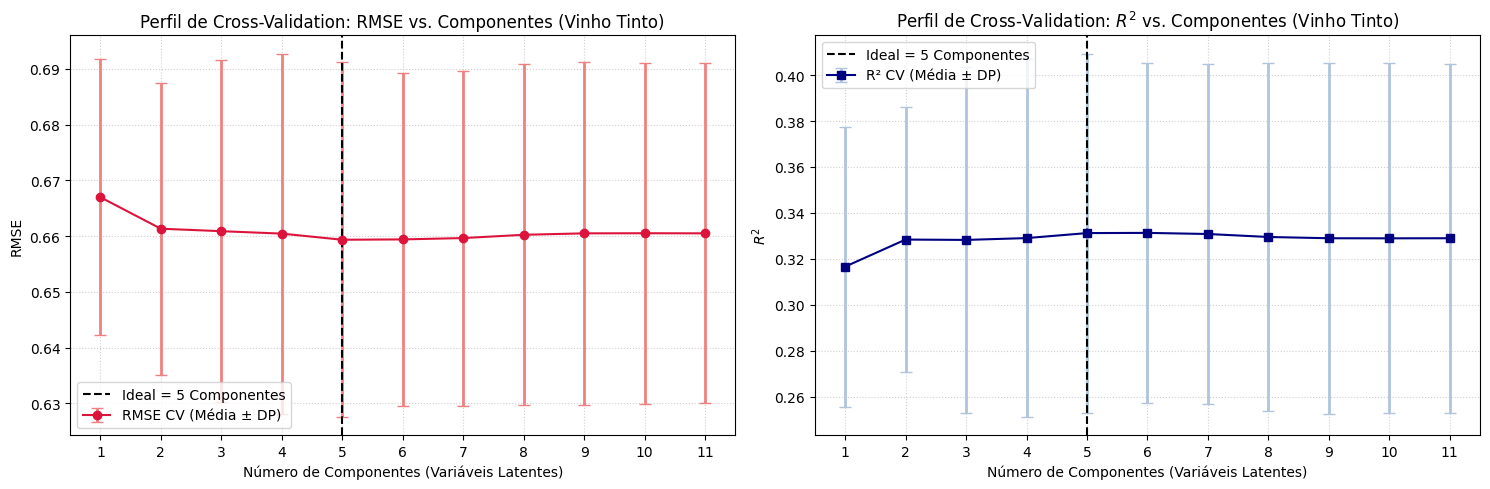

In [58]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Perfil do RMSE
axes[0].errorbar(
    df_cv_pls_red['Num_Componentes'],
    df_cv_pls_red['RMSE_mean'],
    yerr=df_cv_pls_red['RMSE_std'],
    fmt='-o', color='crimson', ecolor='lightcoral', elinewidth=2, capsize=4, markersize=6,
    label='RMSE CV (Média ± DP)'
)
axes[0].axvline(best_comp_red, color='black', linestyle='--', lw=1.5,
                label=f'Ideal = {best_comp_red} Componentes')
axes[0].set_xticks(df_cv_pls_red['Num_Componentes'])
axes[0].set_xlabel("Número de Componentes (Variáveis Latentes)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Perfil de Cross-Validation: RMSE vs. Componentes (Vinho Tinto)")
axes[0].grid(True, which='both', linestyle=':', alpha=0.6)
axes[0].legend()

# Perfil do R²
axes[1].errorbar(
    df_cv_pls_red['Num_Componentes'],
    df_cv_pls_red['R2_mean'],
    yerr=df_cv_pls_red['R2_std'],
    fmt='-s', color='navy', ecolor='lightsteelblue', elinewidth=2, capsize=4, markersize=6,
    label='R² CV (Média ± DP)'
)
axes[1].axvline(best_comp_red, color='black', linestyle='--', lw=1.5,
                label=f'Ideal = {best_comp_red} Componentes')
axes[1].set_xticks(df_cv_pls_red['Num_Componentes'])
axes[1].set_xlabel("Número de Componentes (Variáveis Latentes)")
axes[1].set_ylabel("$R^2$")
axes[1].set_title("Perfil de Cross-Validation: $R^2$ vs. Componentes (Vinho Tinto)")
axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()


Avaliando PLS para 30% de teste (Vinho Tinto):

In [59]:

pls_final_red = PLSRegression(n_components=best_comp_red)


pls_final_red.fit(X_train_red_scaled, y_train_red)


y_pred_ts_pls = pls_final_red.predict(X_test_red_scaled).flatten()


rmse_ts_pls = float(np.sqrt(mean_squared_error(y_test_red, y_pred_ts_pls)))
r2_ts_pls = float(r2_score(y_test_red, y_pred_ts_pls))


print(f"Avaliacao no conjunto de teste (PLS de vinho tinto com {best_comp_red} comp.)")

print(f"PLS Final: RMSE: {rmse_ts_pls:.6f} | R²: {r2_ts_pls:.6f}")


Avaliacao no conjunto de teste (PLS de vinho tinto com 5 comp.)
PLS Final: RMSE: 0.640178 | R²: 0.353607


Calculando numero de componentes para vinho branco:

In [60]:

df_cv_pls_white, best_comp_white = cross_validate_pls(
    X_train=X_train_white_scaled,
    y_train=y_train_white,
    max_components=X_train_white_scaled.shape[1],
    k=5,
    random_state=42
)


print("Resultados da Validacao Cruzada (vinho branco)")
print(df_cv_pls_white[['Num_Componentes', 'RMSE_mean', 'RMSE_std', 'R2_mean', 'R2_std']].to_string(index=False))

print("\n")
best_row_pls_white = df_cv_pls_white[df_cv_pls_white['Num_Componentes'] == best_comp_white].iloc[0]
print(f"Número ótimo de componentes (vinho branco) : {best_comp_white}")
print(f"Desempenho no CV                     : RMSE = {best_row_pls_white['RMSE_mean']:.4f} ± {best_row_pls_white['RMSE_std']:.4f} | R² = {best_row_pls_white['R2_mean']:.4f} ± {best_row_pls_white['R2_std']:.4f}")


Resultados da Validacao Cruzada (vinho branco)
 Num_Componentes  RMSE_mean  RMSE_std  R2_mean   R2_std
               1   0.800534  0.014210 0.194000 0.022091
               2   0.759870  0.020469 0.273785 0.029272
               3   0.750880  0.020842 0.290873 0.029086
               4   0.749725  0.020247 0.293085 0.027254
               5   0.749620  0.020789 0.293277 0.028149
               6   0.749903  0.021105 0.292724 0.029177
               7   0.751601  0.022136 0.289435 0.032960
               8   0.751874  0.022261 0.288906 0.033454
               9   0.752051  0.022478 0.288559 0.034067
              10   0.752057  0.022483 0.288547 0.034078
              11   0.752060  0.022484 0.288542 0.034080


Número ótimo de componentes (vinho branco) : 5
Desempenho no CV                     : RMSE = 0.7496 ± 0.0208 | R² = 0.2933 ± 0.0281


Entendendo perfil do numero de componentes no vinho branco:

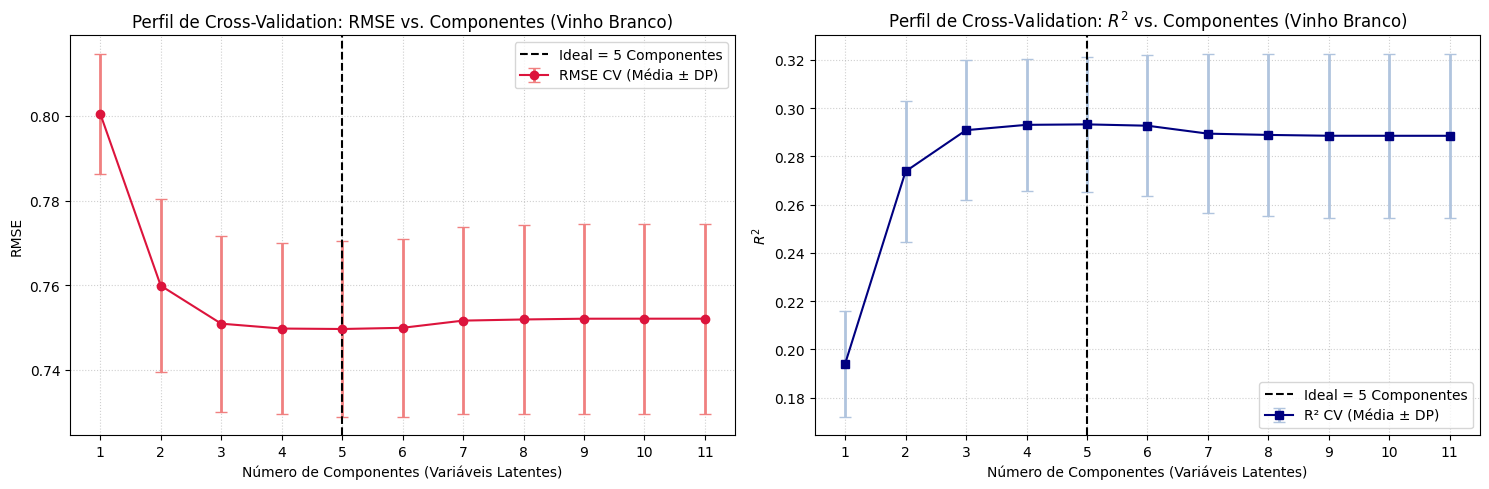

In [61]:


fig, axes = plt.subplots(1, 2, figsize=(15, 5))


axes[0].errorbar(
    df_cv_pls_white['Num_Componentes'],
    df_cv_pls_white['RMSE_mean'],
    yerr=df_cv_pls_white['RMSE_std'],
    fmt='-o', color='crimson', ecolor='lightcoral', elinewidth=2, capsize=4, markersize=6,
    label='RMSE CV (Média ± DP)'
)
axes[0].axvline(best_comp_white, color='black', linestyle='--', lw=1.5,
                label=f'Ideal = {best_comp_white} Componentes')
axes[0].set_xticks(df_cv_pls_white['Num_Componentes'])
axes[0].set_xlabel("Número de Componentes (Variáveis Latentes)")
axes[0].set_ylabel("RMSE")
axes[0].set_title("Perfil de Cross-Validation: RMSE vs. Componentes (Vinho Branco)")
axes[0].grid(True, which='both', linestyle=':', alpha=0.6)
axes[0].legend()


axes[1].errorbar(
    df_cv_pls_white['Num_Componentes'],
    df_cv_pls_white['R2_mean'],
    yerr=df_cv_pls_white['R2_std'],
    fmt='-s', color='navy', ecolor='lightsteelblue', elinewidth=2, capsize=4, markersize=6,
    label='R² CV (Média ± DP)'
)
axes[1].axvline(best_comp_white, color='black', linestyle='--', lw=1.5,
                label=f'Ideal = {best_comp_white} Componentes')
axes[1].set_xticks(df_cv_pls_white['Num_Componentes'])
axes[1].set_xlabel("Número de Componentes (Variáveis Latentes)")
axes[1].set_ylabel("$R^2$")
axes[1].set_title("Perfil de Cross-Validation: $R^2$ vs. Componentes (Vinho Branco)")
axes[1].grid(True, which='both', linestyle=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()


Avaliando PLS para 30% de teste (Vinho Tinto):

In [62]:

pls_final_white = PLSRegression(n_components=best_comp_white)

pls_final_white.fit(X_train_white_scaled, y_train_white)


y_pred_ts_pls_white = pls_final_white.predict(X_test_white_scaled).flatten()


rmse_ts_pls_white = float(np.sqrt(mean_squared_error(y_test_white, y_pred_ts_pls_white)))
r2_ts_pls_white = float(r2_score(y_test_white, y_pred_ts_pls_white))


print(f"Avaliacao no conjunto de teste (PLS de vinho branco com {best_comp_white} comp.)")

print(f"PLS Final:  RMSE: {rmse_ts_pls_white:.6f}, R²: {r2_ts_pls_white:.6f}")

Avaliacao no conjunto de teste (PLS de vinho branco com 5 comp.)
PLS Final:  RMSE: 0.732881, R²: 0.288621


4. Redes Neurais

In [63]:
# Arquitetura: 2 camadas ocultas com 50 neurónios cada.
# solver='adam' é ok para conjuntos de dados de média dimensão.
# max_iter=2000 e early_stopping=True ajudam a evitar o overfitting.

mlp_red = MLPRegressor(
    hidden_layer_sizes=(50, 50),
    activation='relu',
    solver='adam',
    max_iter=2000,
    random_state=42,
    early_stopping=True
)


mlp_red.fit(X_train_red_scaled, y_train_red)


y_pred_ts_mlp = mlp_red.predict(X_test_red_scaled)

rmse_ts_mlp = float(np.sqrt(mean_squared_error(y_test_red, y_pred_ts_mlp)))
r2_ts_mlp = float(r2_score(y_test_red, y_pred_ts_mlp))

print("Avaliacao no conjunto de teste (Rede Neural)")

print(f"MLP Tinto (Rede Neural) -> RMSE: {rmse_ts_mlp:.6f} | R²: {r2_ts_mlp:.6f}")


Avaliacao no conjunto de teste (Rede Neural)
MLP Tinto (Rede Neural) -> RMSE: 0.657648 | R²: 0.317847


Fazendo o mesmo para o vinho branco:

In [64]:
mlp_white = MLPRegressor(
    hidden_layer_sizes=(50, 50),
    activation='relu',
    solver='adam',
    max_iter=2000,
    random_state=42,
    early_stopping=True
)


mlp_white.fit(X_train_white_scaled, y_train_white)


y_pred_ts_mlp_white = mlp_white.predict(X_test_white_scaled)

rmse_ts_mlp_white = float(np.sqrt(mean_squared_error(y_test_white, y_pred_ts_mlp_white)))
r2_ts_mlp_white = float(r2_score(y_test_white, y_pred_ts_mlp_white))


print("Avaliacao no conjunto de teste (Rede Neural)")

print(f"MLP Branco (Rede Neural) -> RMSE: {rmse_ts_mlp_white:.6f} | R²: {r2_ts_mlp_white:.6f}")


Avaliacao no conjunto de teste (Rede Neural)
MLP Branco (Rede Neural) -> RMSE: 0.697569 | R²: 0.355521


Comparando valores de RMSE e R^2 (Vinho Tinto):

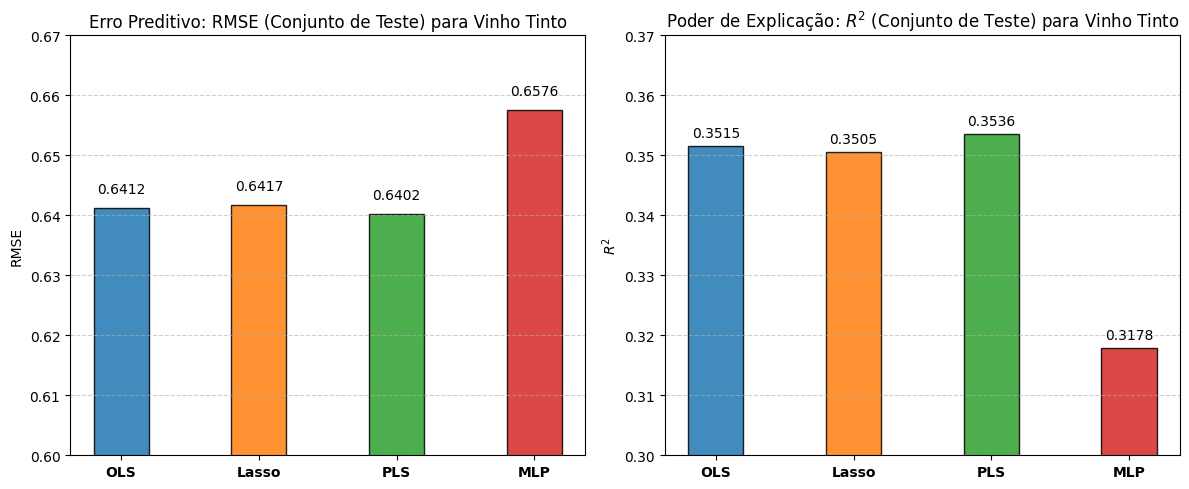

In [65]:
def plot_metrics_comparison():
    models = ['OLS', 'Lasso', 'PLS', 'MLP']


    rmse_values = [rmse_red, rmse_ts_sc, rmse_ts_pls, rmse_ts_mlp]
    r2_values = [r2_red, r2_ts_sc, r2_ts_pls, r2_ts_mlp]

    x = np.arange(len(models))
    width = 0.4

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']


    bars_rmse = axes[0].bar(x, rmse_values, width, color=colors, edgecolor='black', alpha=0.85)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(models, fontweight='bold')
    axes[0].set_title('Erro Preditivo: RMSE (Conjunto de Teste) para Vinho Tinto')
    axes[0].set_ylabel('RMSE')
    axes[0].set_ylim(0.60, 0.67)
    axes[0].grid(axis='y', linestyle='--', alpha=0.6)


    for bar in bars_rmse:
        yval = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.002,
                     f'{yval:.4f}', ha='center', va='bottom', fontsize=10)


    bars_r2 = axes[1].bar(x, r2_values, width, color=colors, edgecolor='black', alpha=0.85)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(models, fontweight='bold')
    axes[1].set_title('Poder de Explicação: $R^2$ (Conjunto de Teste) para Vinho Tinto')
    axes[1].set_ylabel('$R^2$')
    axes[1].set_ylim(0.30, 0.37)
    axes[1].grid(axis='y', linestyle='--', alpha=0.6)


    for bar in bars_r2:
        yval = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.001,
                     f'{yval:.4f}', ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.savefig('comparacao_modelos_tinto.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_metrics_comparison()

Vinho Branco:

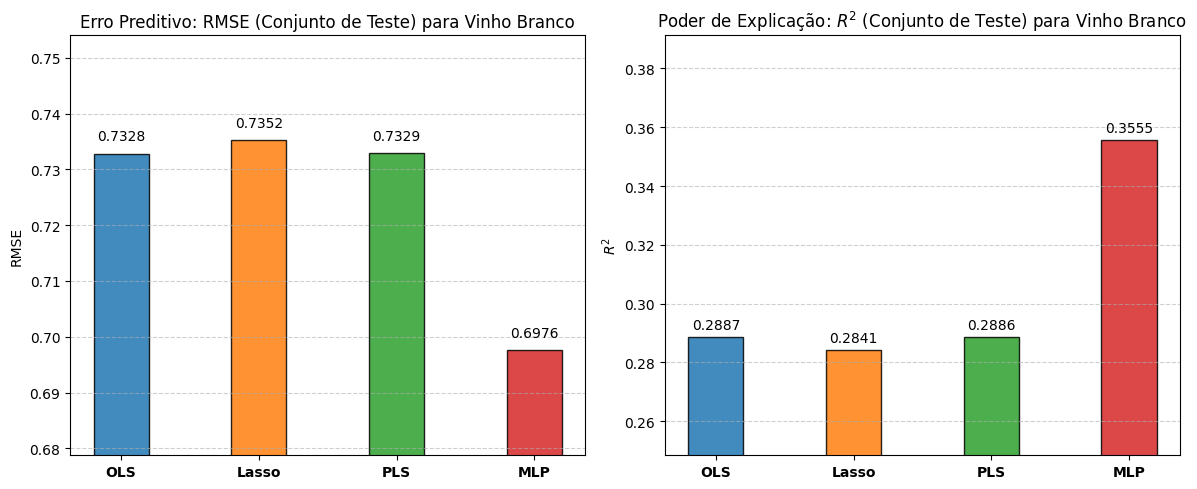

In [66]:
def plot_metrics_comparison_white():
    models = ['OLS', 'Lasso', 'PLS', 'MLP']


    rmse_values = [rmse_white, rmse_ts_sc_white, rmse_ts_pls_white, rmse_ts_mlp_white]
    r2_values = [r2_white, r2_ts_sc_white, r2_ts_pls_white, r2_ts_mlp_white]

    x = np.arange(len(models))
    width = 0.4

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']


    bars_rmse = axes[0].bar(x, rmse_values, width, color=colors, edgecolor='black', alpha=0.85)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(models, fontweight='bold')
    axes[0].set_title('Erro Preditivo: RMSE (Conjunto de Teste) para Vinho Branco')
    axes[0].set_ylabel('RMSE')


    min_rmse, max_rmse = min(rmse_values), max(rmse_values)
    margem_rmse = (max_rmse - min_rmse) * 0.5 if max_rmse != min_rmse else 0.05
    axes[0].set_ylim(min_rmse - margem_rmse, max_rmse + margem_rmse)
    axes[0].grid(axis='y', linestyle='--', alpha=0.6)


    for bar in bars_rmse:
        yval = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2, yval + (margem_rmse * 0.1),
                     f'{yval:.4f}', ha='center', va='bottom', fontsize=10)


    bars_r2 = axes[1].bar(x, r2_values, width, color=colors, edgecolor='black', alpha=0.85)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(models, fontweight='bold')
    axes[1].set_title('Poder de Explicação: $R^2$ (Conjunto de Teste) para Vinho Branco')
    axes[1].set_ylabel('$R^2$')


    min_r2, max_r2 = min(r2_values), max(r2_values)
    margem_r2 = (max_r2 - min_r2) * 0.5 if max_r2 != min_r2 else 0.05
    axes[1].set_ylim(max(0, min_r2 - margem_r2), max_r2 + margem_r2)
    axes[1].grid(axis='y', linestyle='--', alpha=0.6)


    for bar in bars_r2:
        yval = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2, yval + (margem_r2 * 0.05),
                     f'{yval:.4f}', ha='center', va='bottom', fontsize=10)

    plt.tight_layout()
    plt.savefig('comparacao_modelos_branco.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_metrics_comparison_white()